In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [63]:
dataset = pd.read_csv("C:/Users/user/Downloads/classification data/Social_Network_Ads.csv").values
X = dataset[:,:-1]
y = dataset[:,-1]

In [64]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

In [65]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ab = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=1),
                       n_estimators=5, learning_rate=0.8, algorithm='SAMME')
ab.fit(X_train,y_train)

C:\Users\user\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


,estimator,DecisionTreeC...andom_state=1)
,n_estimators,5
,learning_rate,0.8
,algorithm,'SAMME'
,random_state,None
,criterion,'gini'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [66]:
y_train_pred = ab.predict(X_train)
y_test_pred = ab.predict(X_test)

In [67]:
from sklearn.metrics import accuracy_score
train_acc = accuracy_score(y_train,y_train_pred)
test_acc = accuracy_score(y_test,y_test_pred)
print('train accuracy: ',train_acc*100)
print('test accuracy: ',test_acc*100)

train accuracy:  93.0
test accuracy:  89.0


In [68]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y_test_pred)

array([[50,  8],
       [ 3, 39]], dtype=int64)

In [69]:
##(10)92,89
##(5)93,87
##(2)93,87
##(50)95,89
##100 95.7,88

In [70]:
x0_min = X[:,0].min()-2
x0_max = X[:,0].max()+2

x1_min = X[:,1].min()-1000
x1_max = X[:,1].max()+1000

x0 = np.linspace(x0_min,x0_max,500)
x0 = np.linspace(x0_min,x0_max,500)

x1 = np.linspace(x1_min,x1_max,500)
x1 = np.linspace(x1_min,x1_max,500)

X0,X1 = np.meshgrid(x0,x1)

In [71]:
X0_1D = X0.reshape(-1,1)
X1_1D = X1.reshape(-1,1)
X0_X1 = np.concatenate((X0_1D,X1_1D),axis=1)

In [72]:
y_grid = ab.predict(X0_X1)

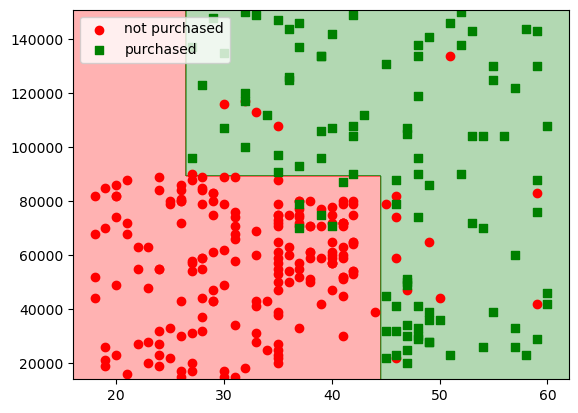

In [73]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])
y_ab = y_grid.reshape(X0.shape)
plt.contourf(X0, X1, y_ab, cmap=class_color, alpha=0.3)

X0_train = X_train[y_train==0,:]
X1_train= X_train[y_train ==1,:]

plt.scatter(X0_train[:,0], X0_train[:,1], color='red', label='not purchased')
plt.scatter(X1_train[:,0], X1_train[:,1], color='green', marker='s', label='purchased')
plt.legend()

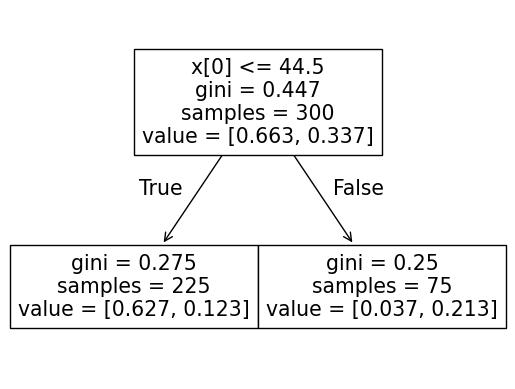

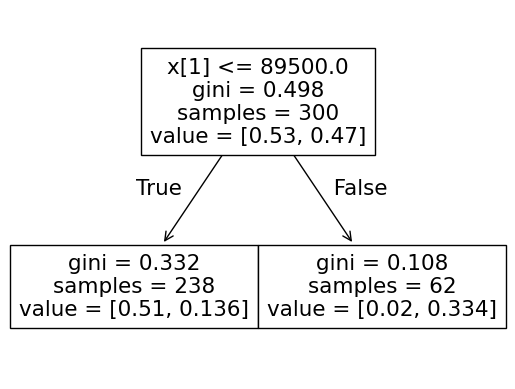

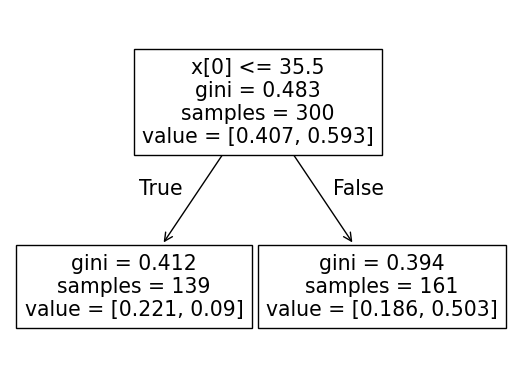

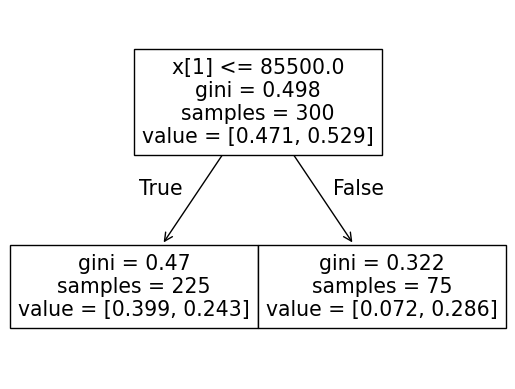

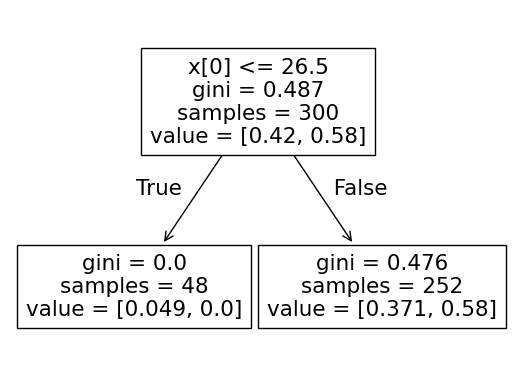

In [76]:
from sklearn.tree import plot_tree
for i in range(len(ab.estimators_)):
    plot_tree(ab.estimators_[i])
    plt.show()

In [77]:
len(ab.estimators_)

5

In [83]:
print(ab.estimators_[1].tree_.children_left)
print(ab.estimators_[1].tree_.children_right)

[ 1 -1 -1]
[ 2 -1 -1]


In [86]:
ab.estimators_[1].tree_.feature

array([ 1, -2, -2], dtype=int64)

In [90]:
for i in range(len(ab.estimators_)):
    print('* tree index: ', i)
    print(ab.estimators_[i].tree_.feature)
    print(ab.estimators_[i].tree_.threshold)

* tree index:  0
[ 0 -2 -2]
[44.5 -2.  -2. ]
* tree index:  1
[ 1 -2 -2]
[ 8.95e+04 -2.00e+00 -2.00e+00]
* tree index:  2
[ 0 -2 -2]
[35.5 -2.  -2. ]
* tree index:  3
[ 1 -2 -2]
[ 8.55e+04 -2.00e+00 -2.00e+00]
* tree index:  4
[ 0 -2 -2]
[26.5 -2.  -2. ]
